## load and preprocess some images

load two sample images, crop them to 70x120 pixels and scale their pixel intensities to the 0-1 range.

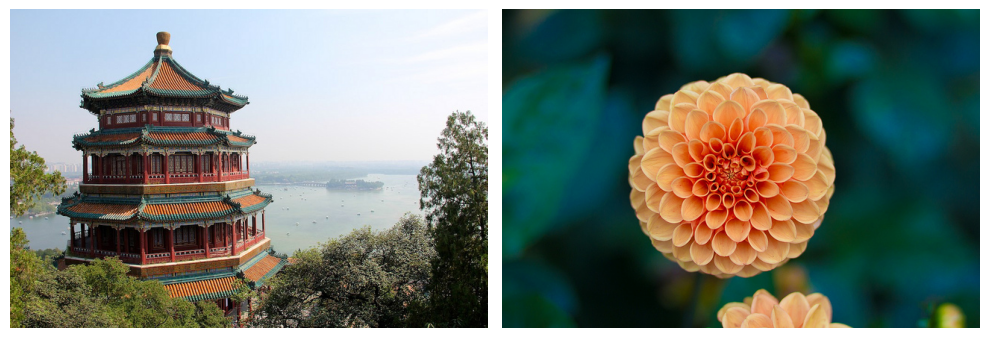

In [2]:
from sklearn.datasets import load_sample_images
import keras

images = load_sample_images()["images"]

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

for i, image in enumerate(images):
    plt.subplot(1, len(images), i + 1)
    plt.imshow(image)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [3]:

images = keras.layers.CenterCrop(height=70, width=120)(images)
images = keras.layers.Rescaling(scale=1 / 255)(images)

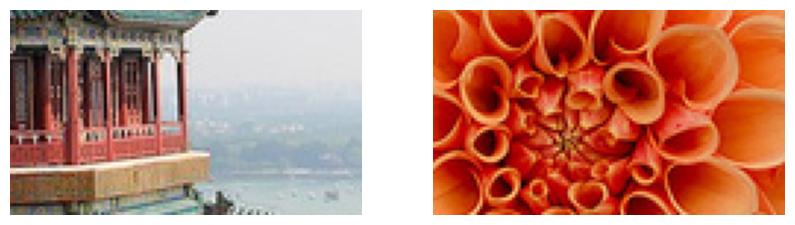

In [4]:
plt.figure(figsize=(10, 4))

for i, image in enumerate(images):
    plt.subplot(1, len(images), i + 1)
    plt.imshow(image)
    plt.axis("off")

plt.show()

In [5]:
# create the convolutional layer. 32 filters of size 7x7

conv_layer = keras.layers.Conv2D(filters=32, kernel_size=7)

# apply to the images

fmaps = conv_layer(images)

# use padding. 'same'ArithmeticError

conv_layer = keras.layers.Conv2D(filters=32, kernel_size=7, padding='same')

fmaps = conv_layer(images)



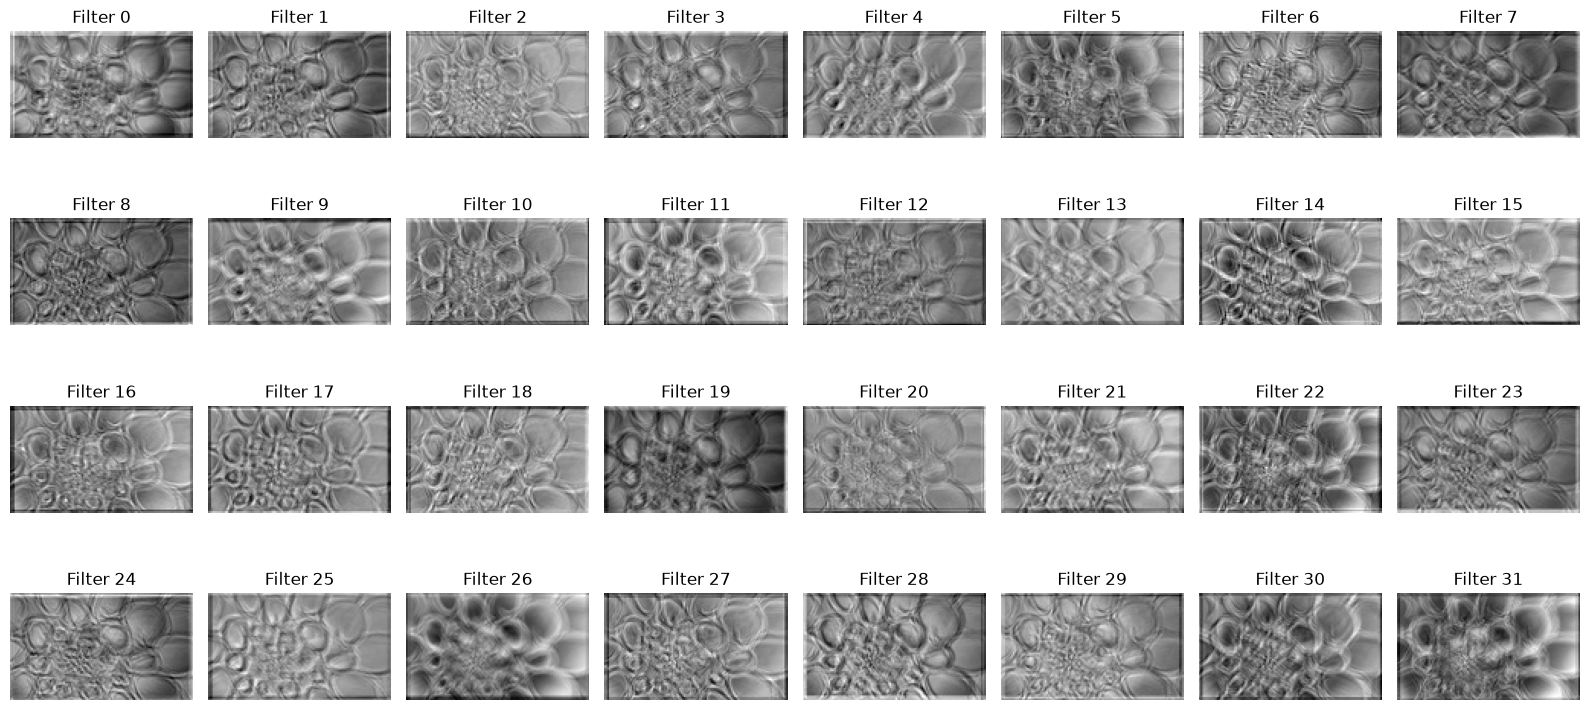

In [6]:
import numpy as np
import matplotlib.pyplot as plt

maps = np.asarray(fmaps)[1]
n_maps = maps.shape[-1]
cols = min(8, n_maps)

plt.figure(figsize=(cols * 2, int(np.ceil(n_maps / cols)) * 2))

for i in range(n_maps):
    plt.subplot(int(np.ceil(n_maps / cols)), cols, i + 1)
    plt.imshow(maps[:, :, i], cmap="gray")
    plt.title(f"Filter {i}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
kernels, biases = conv_layer.get_weights()
print(
  kernels.shape,
  "\n",
  biases.shape
)

# kernels.shape is (kernel_height, kernel_width, input_channels, output_channels).
# biases.shape is (output_channels,)

(7, 7, 3, 32) 
 (32,)


In [8]:
max_pool = keras.layers.MaxPool2D(pool_size=2)

global_avg_pool = keras.layers.GlobalAveragePooling2D()


## Voorbeeld: cnn fashion mnist

In [9]:
fashion_mnist_dataset = keras.datasets.fashion_mnist.load_data()



In [10]:
fashion_mnist_dataset[1]

(array([[[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        ...,
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],

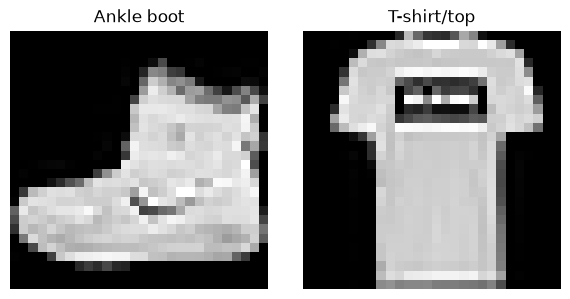

In [11]:
train_images, train_labels = fashion_mnist_dataset[0]
test_images, test_labels = fashion_mnist_dataset[1]

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
for i, ax in enumerate(axes):
    ax.imshow(train_images[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(class_names[train_labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
from functools import partial

DefaultConv2D = partial(
  keras.layers.Conv2D,
  kernel_size=3,
  padding="same",
  activation="relu",
  kernel_initializer="he_normal")

In [13]:
def get_model():
  model = keras.Sequential([
    keras.layers.Input(shape=(28, 28, 1)),
    DefaultConv2D(filters=64, kernel_size=7),
    keras.layers.MaxPool2D(), # default size is 2x2
    DefaultConv2D(filters=128),
    DefaultConv2D(filters=128),
    keras.layers.MaxPool2D(),
    DefaultConv2D(filters=256),
    DefaultConv2D(filters=256),
    keras.layers.MaxPool2D(),
    keras.layers.Flatten(),
    keras.layers.Dense(units=128, activation="relu", kernel_initializer="he_normal"),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(units=64, activation="relu", kernel_initializer="he_normal"),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(units=10, activation="softmax")
  ])
  
  return model

model = get_model()

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │         3,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 7, 7, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,413,834 (5.39 MB)

 Trainable params: 1,413,834 (5.39 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model.compile(
  optimizer="adam",
  loss="sparse_categorical_crossentropy",
  metrics=["accuracy"]
)

In [ ]:
history = model.fit(
  
)